# Xception Deepfake Detection with ART FGSM Adversarial Training

**Revised notebook:** preserves the uploaded dataset discovery and preprocessing design while fixing ART setup, repeated path scanning, duplicate model initialization, benchmark weight changes, memory use during clean/adversarial backward passes, and attack-time BatchNorm updates.

Run from top to bottom in Kaggle. A complete training run has not been verified in this environment; first run the short benchmark and inspect its estimate before committing to all epochs. Test data is only used in the final evaluation/visualization cells.

In [1]:
# [FIX] Install ART before importing the rest of the ML stack.
# Kaggle Internet must be enabled if ART is not already installed.
import importlib.util, subprocess, sys
if importlib.util.find_spec("art") is None:
    print("ART not found; installing adversarial-robustness-toolbox...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "adversarial-robustness-toolbox"])
else:
    print("ART is already installed.")


ART not found; installing adversarial-robustness-toolbox...


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 14.5 MB/s eta 0:00:00


In [2]:
import os
import glob
import random
import cv2
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import timm
import time, csv, copy, warnings

# Reproducibility (cuDNN benchmark is enabled later for throughput).
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


In [3]:
# 1. Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [4]:

import art
from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import FastGradientMethod

print("ART imported successfully")
print("ART version:", getattr(art, "__version__", "unknown"))


ART imported successfully
ART version: 1.20.1


In [5]:
# 2. Aggressive Social Media Compression Function
def apply_social_media_compression(img_bgr):
    """
    Simulates aggressive social media pipeline: 
    Downscale -> Chroma Subsampling (JPEG) -> Gaussian Blur -> Upscale
    """
    h, w, _ = img_bgr.shape
    
    # Step 1: Aggressive Downscaling (mimicking platform resizing)
    scale_factor = random.uniform(1.0, 1.0)
    new_h, new_w = int(h * scale_factor), int(w * scale_factor)
    img_resized = cv2.resize(img_bgr, (new_w, new_h), interpolation=cv2.INTER_AREA)
    img_resized = cv2.resize(img_resized, (w, h), interpolation=cv2.INTER_LINEAR)
    
    # Step 2: Apply a mild Gaussian Blur
    if random.random() < 0.7:
        img_resized = cv2.GaussianBlur(img_resized, (5, 5), 0)
        
    # Step 3: Extreme JPEG Compression with Chroma Subsampling
    quality = random.randint(10, 25)
    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    _, encimg = cv2.imencode('.jpg', img_resized, encode_param)
    decimg_bgr = cv2.imdecode(encimg, 1)
    
    # Convert to RGB for PIL / PyTorch
    return cv2.cvtColor(decimg_bgr, cv2.COLOR_BGR2RGB)

In [6]:

# [FIX] Dataset discovery is cached; folder and image-extension matching is case-insensitive.
class BalancedDeepfakeDataset(Dataset):
    _path_cache = {}

    def __init__(
        self,
        split='train',
        base_dir='/kaggle/input',
        transform=None,
        seed=42,
        compression_prob=0.5
    ):
        self.transform = transform
        self.compression_prob = compression_prob
        self.image_paths, self.labels = [], []
        self.rng = random.Random(seed)

        self._temp_data = {
            'celeb': {0: [], 1: []},
            '140k': {0: [], 1: []},
            'ffpp': {0: [], 1: []}
        }

        print(f"[{split.upper()}] Discovering datasets under {base_dir}...")
        dataset_paths = self._auto_discover_paths(base_dir)
        print(f"[{split.upper()}] Dataset roots: {dataset_paths}")

        self._load_celebdf(dataset_paths['celeb'], split)
        self._load_140k(dataset_paths['140k'], split)
        self._load_ffpp(dataset_paths['ffpp'], split)
        self._balance_and_merge(split)

    def _auto_discover_paths(self, base_dir):
        key = os.path.abspath(base_dir)

        if key in self._path_cache:
            print(f"Using cached dataset discovery for {base_dir}")
            return self._path_cache[key].copy()

        paths = {'celeb': None, 'ffpp': None, '140k': None}

        wanted = {
            'celeb_v2': 'celeb',
            'dataset_processed_split': 'ffpp',
            'real-vs-fake': '140k'
        }

        for root, dirs, files in os.walk(base_dir):
            lower_to_original = {d.lower(): d for d in dirs}

            for dirname, key_name in wanted.items():
                if (
                    paths[key_name] is None
                    and dirname in lower_to_original
                ):
                    paths[key_name] = os.path.join(
                        root, lower_to_original[dirname]
                    )

            if all(paths.values()):
                break

        self._path_cache[key] = paths.copy()
        return paths

    @staticmethod
    def _child_dir(parent, candidates):
        if not parent or not os.path.isdir(parent):
            return None

        lookup = {
            name.lower(): name
            for name in os.listdir(parent)
            if os.path.isdir(os.path.join(parent, name))
        }

        for candidate in candidates:
            if candidate.lower() in lookup:
                return os.path.join(parent, lookup[candidate.lower()])

        return None

    def _add_from_folder(self, dataset_name, folder_path, label):
        if folder_path and os.path.isdir(folder_path):
            valid_ext = {'.png', '.jpg', '.jpeg', '.webp', '.bmp'}

            try:
                for entry in os.scandir(folder_path):
                    if (
                        entry.is_file()
                        and os.path.splitext(entry.name)[1].lower() in valid_ext
                    ):
                        self._temp_data[dataset_name][label].append(
                            entry.path
                        )
            except OSError as exc:
                print(f"Warning: could not scan {folder_path}: {exc}")

    def _load_celebdf(self, base_path, split):
        split_map = {
            'train': ('Train', 'train'),
            'val': ('Val', 'val', 'valid'),
            'test': ('Test', 'test')
        }

        split_path = self._child_dir(
            base_path, split_map.get(split, ())
        )

        if not split_path:
            print(f"[{split.upper()}] Celeb-DF split not found.")
            return

        real_dir = self._child_dir(
            split_path, ('real', 'original', 'authentic')
        )
        fake_dir = self._child_dir(
            split_path, ('fake', 'manipulated', 'deepfake')
        )

        self._add_from_folder('celeb', real_dir, 0)
        self._add_from_folder('celeb', fake_dir, 1)

    def _load_140k(self, base_path, split):
        split_map = {
            'train': ('train',),
            'val': ('valid', 'val', 'validation'),
            'test': ('test',)
        }

        split_path = self._child_dir(
            base_path, split_map.get(split, ())
        )

        if not split_path:
            print(f"[{split.upper()}] 140K split not found.")
            return

        real_dir = self._child_dir(
            split_path, ('real', 'real_images', 'original')
        )
        fake_dir = self._child_dir(
            split_path, ('fake', 'fake_images', 'generated')
        )

        self._add_from_folder('140k', real_dir, 0)
        self._add_from_folder('140k', fake_dir, 1)

    def _load_ffpp(self, base_path, split):
        # Support common validation split names.
        split_candidates = {
            'train': ('train',),
            'val': ('val', 'valid', 'validation'),
            'test': ('test',)
        }

        split_path = self._child_dir(
            base_path, split_candidates.get(split, (split,))
        )

        if not split_path:
            print(
                f"[{split.upper()}] FFPP split not found: {base_path}"
            )
            return

        # Explicitly recognized authentic/original image folders.
        real_names = {
            'real',
            'original',
            'authentic',
            'real_videos',
            'original_sequences'
        }

        # FFPP manipulation-method folders.
        fake_names = {
            'fake',
            'manipulated',
            'deepfake',
            'fake_videos',
            'manipulated_sequences',
            'face2face',
            'deepfakes',
            'deepfakedetection',
            'neuraltextures',
            'faceshifter',
            'faceswap'
        }

        for class_dir in os.listdir(split_path):
            dir_path = os.path.join(split_path, class_dir)

            if not os.path.isdir(dir_path):
                continue

            name = class_dir.strip().lower()

            if name in real_names:
                label = 0
            elif name in fake_names:
                label = 1
            else:
                print(
                    f"[{split.upper()}] Skipping unrecognized "
                    f"FFPP folder: {class_dir!r}"
                )
                continue

            self._add_from_folder('ffpp', dir_path, label)

        print(
            f"[{split.upper()}] FFPP images collected: "
            f"real={len(self._temp_data['ffpp'][0])}, "
            f"fake={len(self._temp_data['ffpp'][1])}"
        )

    def _balance_and_merge(self, split):
        available = {}

        for ds_name, labels in self._temp_data.items():
            n_real = len(labels[0])
            n_fake = len(labels[1])

            if n_real and n_fake:
                available[ds_name] = labels
            else:
                print(
                    f"[{split.upper()}] Skipping {ds_name}: "
                    f"real={n_real}, fake={n_fake} "
                    f"(both classes required)."
                )

        if not available:
            raise RuntimeError(
                f"No usable dataset sources found for split={split!r}; "
                "check dataset roots and class folder names."
            )

        min_count = min(
            min(len(labels[0]), len(labels[1]))
            for labels in available.values()
        )

        print(
            f"[{split.upper()}] Balancing each available source "
            f"to {min_count} images per class..."
        )

        combined = []

        for ds_name, labels in available.items():
            for label, paths in labels.items():
                selected = self.rng.sample(paths, min_count)
                combined.extend((path, label) for path in selected)

        self.rng.shuffle(combined)

        self.image_paths = [path for path, _ in combined]
        self.labels = [int(label) for _, label in combined]

        counts = {
            0: self.labels.count(0),
            1: self.labels.count(1)
        }

        print(
            f"Final {split} dataset size: {len(self.image_paths)}; "
            f"label counts: {counts}"
        )

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]

        img_bgr = cv2.imread(img_path)

        if img_bgr is None:
            raise RuntimeError(f"Could not decode image: {img_path}")

        if self.rng.random() < self.compression_prob:
            img_rgb = apply_social_media_compression(img_bgr)
        else:
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        img_pil = Image.fromarray(img_rgb)

        if self.transform:
            img_tensor = self.transform(img_pil)
        else:
            img_tensor = transforms.ToTensor()(img_pil)

        return img_tensor, torch.tensor(label, dtype=torch.long)


In [7]:
# 4. Define Transforms for Xception (299x299)
def get_data_transforms(img_size=299):
    norm_mean = [0.485, 0.456, 0.406]
    norm_std = [0.229, 0.224, 0.225]

    train_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomCrop(img_size, padding=4, padding_mode='reflect'),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_mean, std=norm_std)
    ])

    val_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_mean, std=norm_std)
    ])

    return train_transform, val_transform

In [8]:
# [FIX] Full discovered datasets are retained; batch size/workers are configurable for Kaggle GPU RAM.
train_transform, val_transform = get_data_transforms(img_size=299)
BATCH_SIZE = 16
NUM_WORKERS = 2
loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                     pin_memory=torch.cuda.is_available(),
                     persistent_workers=(NUM_WORKERS > 0))
train_dataset = BalancedDeepfakeDataset(split='train', transform=train_transform, seed=42, compression_prob=0.7)
val_dataset = BalancedDeepfakeDataset(split='val', transform=val_transform, seed=42, compression_prob=0.0)
test_dataset = BalancedDeepfakeDataset(split='test', transform=val_transform, seed=42, compression_prob=0.0)
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)
print(f"Batches/epoch: train={len(train_loader)}, val={len(val_loader)}, test={len(test_loader)}")


[TRAIN] Discovering datasets under /kaggle/input...


[TRAIN] Dataset roots: {'celeb': '/kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2', 'ffpp': '/kaggle/input/datasets/gradientvoyager/faceforensics-c23-extracted-faces-100k/dataset_processed_split', '140k': '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake'}


[TRAIN] FFPP images collected: real=18391, fake=110086
[TRAIN] Balancing each available source to 18391 images per class...


Final train dataset size: 110346; label counts: {0: 55173, 1: 55173}
[VAL] Discovering datasets under /kaggle/input...
Using cached dataset discovery for /kaggle/input
[VAL] Dataset roots: {'celeb': '/kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2', 'ffpp': '/kaggle/input/datasets/gradientvoyager/faceforensics-c23-extracted-faces-100k/dataset_processed_split', '140k': '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake'}


[VAL] FFPP images collected: real=4109, fake=23384
[VAL] Balancing each available source to 4109 images per class...
Final val dataset size: 24654; label counts: {0: 12327, 1: 12327}
[TEST] Discovering datasets under /kaggle/input...
Using cached dataset discovery for /kaggle/input
[TEST] Dataset roots: {'celeb': '/kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2', 'ffpp': '/kaggle/input/datasets/gradientvoyager/faceforensics-c23-extracted-faces-100k/dataset_processed_split', '140k': '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake'}


[TEST] FFPP images collected: real=3944, fake=22332
[TEST] Balancing each available source to 3944 images per class...
Final test dataset size: 23664; label counts: {0: 11832, 1: 11832}
Batches/epoch: train=6897, val=1541, test=1479


In [9]:
# [FIX] The final SpatialDeepfakeDetector is initialized once in the model setup cell below.
# This cell intentionally does not create a throwaway Xception instance.

In [10]:
# Input batch sanity check (model output is checked after the final model is initialized).
images, labels = next(iter(train_loader))
print(f"Batch images shape: {tuple(images.shape)} (expected [B, 3, 299, 299])")
print(f"Batch labels shape: {tuple(labels.shape)}; unique labels={labels.unique().tolist()}")
assert images.ndim == 4 and images.shape[1:] == (3, 299, 299)
assert set(labels.unique().tolist()).issubset({0, 1})

Batch images shape: (16, 3, 299, 299) (expected [B, 3, 299, 299])
Batch labels shape: (16,); unique labels=[0, 1]


In [11]:
# [FIX] Reuse the batch loaded in the preceding sanity-check cell; avoid a second disk read.
print("Using the same sanity-check batch for visualization and model-shape checks.")

Using the same sanity-check batch for visualization and model-shape checks.


In [12]:
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import timm

In [13]:
def imshow(inp, title=None):
    """Imshow for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    
    # Un-normalize 
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    
    plt.figure(figsize=(12, 8))
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.axis('off')
    plt.show()

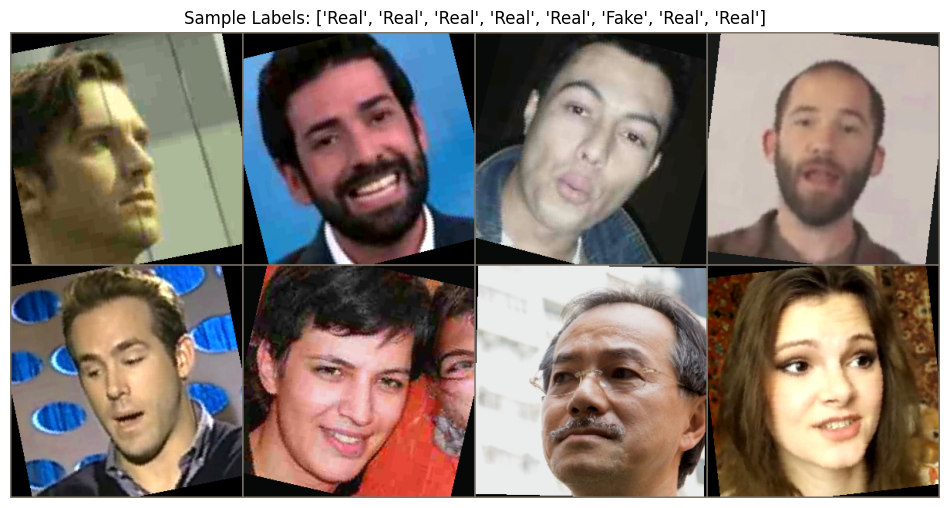

In [14]:
# Grab a single batch
images, labels = next(iter(train_loader))

num_images_to_show = 8
images_to_show = images[:num_images_to_show]
labels_to_show = labels[:num_images_to_show]

out = torchvision.utils.make_grid(images_to_show, nrow=4)
label_mapping = {0: "Real", 1: "Fake"}
titles = [label_mapping[int(label.item())] for label in labels_to_show]

imshow(out, title=f"Sample Labels: {titles}")

In [15]:
# Xception binary classifier with TWO logits (Real=0, Fake=1).
# CrossEntropyLoss and ART therefore use the same class-index label convention.
class SpatialDeepfakeDetector(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model('xception', pretrained=pretrained, num_classes=2)

    def forward(self, x):
        return self.backbone(x)


In [16]:
# Reproducibility and input/label sanity checks
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

assert len(train_dataset) > 0 and len(val_dataset) > 0 and len(test_dataset) > 0, "A dataset split is empty; inspect dataset discovery and class-folder names."
for split_name, ds in [('train', train_dataset), ('val', val_dataset), ('test', test_dataset)]:
    counts = {0: ds.labels.count(0), 1: ds.labels.count(1)}
    print(f"{split_name}: n={len(ds)}, Real(0)={counts[0]}, Fake(1)={counts[1]}")
    assert counts[0] > 0 and counts[1] > 0, f"{split_name} is missing a class."

# Split leakage check: exact file paths must not overlap across splits.
train_paths, val_paths, test_paths = map(lambda ds: set(os.path.realpath(p) for p in ds.image_paths),
                                         (train_dataset, val_dataset, test_dataset))
print(f"Path overlap counts: train/val={len(train_paths & val_paths)}, train/test={len(train_paths & test_paths)}, val/test={len(val_paths & test_paths)}")
assert not (train_paths & val_paths or train_paths & test_paths or val_paths & test_paths), "Exact file paths overlap between splits."
print("Note: exact-path checks do not detect duplicate image content stored under different filenames.")

train: n=110346, Real(0)=55173, Fake(1)=55173
val: n=24654, Real(0)=12327, Fake(1)=12327
test: n=23664, Real(0)=11832, Fake(1)=11832


Path overlap counts: train/val=0, train/test=0, val/test=0
Note: exact-path checks do not detect duplicate image content stored under different filenames.


In [17]:
# [FIX] Initialize the actual final model once; ART, optimizer, training, and evaluation all reference this object.
print("Loading the final pretrained Xception model...")
model = SpatialDeepfakeDetector(pretrained=True).to(device)
images_device = images.to(device)
with torch.no_grad():
    outputs = model(images_device)
print(f"Input shape: {tuple(images_device.shape)}; output shape: {tuple(outputs.shape)}")
assert outputs.shape == (images_device.shape[0], 2), "Expected two logits per image (Real=0, Fake=1)."
del images_device, outputs

Loading the final pretrained Xception model...


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth


Input shape: (16, 3, 299, 299); output shape: (16, 2)


In [18]:
import torch.optim as optim
from tqdm import tqdm
import copy
from torch.optim.lr_scheduler import ReduceLROnPlateau

In [19]:
# Two-class logits -> CrossEntropyLoss; labels are integer class indices (0=Real, 1=Fake).
criterion = nn.CrossEntropyLoss()


In [20]:
# Optimizer for the final model. Verify that the classifier/head parameter group is non-empty.
backbone_params, classifier_params = [], []
for name, param in model.named_parameters():
    if name.endswith('.fc.weight') or name.endswith('.fc.bias') or name in {'backbone.fc.weight','backbone.fc.bias'}:
        classifier_params.append(param)
    else:
        backbone_params.append(param)
if not classifier_params:
    # timm variants may expose the classifier under another name; use get_classifier() parameters.
    head_ids = {id(p) for p in model.backbone.get_classifier().parameters()}
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
    classifier_params = [p for p in model.parameters() if id(p) in head_ids]
assert classifier_params, "Could not identify Xception classifier parameters."
optimizer = optim.AdamW([
    {'params': backbone_params, 'lr': 1e-5},
    {'params': classifier_params, 'lr': 1e-3},
], weight_decay=1e-4)
print(f"Optimizer parameter tensors: backbone={len(backbone_params)}, head={len(classifier_params)}")

Optimizer parameter tensors: backbone=154, head=2


In [21]:
# 3. Early Stopping Class
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0, verbose=True):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False
        self.best_model_wts = None

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            if self.verbose:
                print(f"Validation loss decreased ({self.best_loss:.4f} --> {val_loss:.4f}). Saving model weights...")
            self.best_loss = val_loss
            self.best_model_wts = copy.deepcopy(model.state_dict())
            self.counter = 0
        else:
            self.counter += 1
            print(f"EarlyStopping counter: {self.counter} out of {self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True

In [22]:
# ART FGSM adversarial training. ART receives raw RGB [0,1]; wrapper normalizes to ImageNet space.
# The same final `model` object is wrapped by ART and updated by `optimizer`.
import time, csv, os, copy
from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import FastGradientMethod
from torch.optim.lr_scheduler import ReduceLROnPlateau

EPSILON = 8.0 / 255.0
ADV_LOSS_WEIGHT = 0.5
EPOCHS = 5
PATIENCE = 3
RESUME_TRAINING = False  # Set True only when resuming from this run directory.
RUN_DIR = os.environ.get("XCEPTION_RUN_DIR", "xception_art_fgsm_run")
os.makedirs(RUN_DIR, exist_ok=True)
CHECKPOINT_PATH = os.path.join(RUN_DIR, "best_validation.pt")
RESUME_PATH = os.path.join(RUN_DIR, "resume_state.pt")
HISTORY_PATH = os.path.join(RUN_DIR, "history.csv")
if not RESUME_TRAINING and os.path.exists(RESUME_PATH):
    # Never silently overwrite an earlier run's resume state.
    import datetime
    RUN_DIR = RUN_DIR + "_" + datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    os.makedirs(RUN_DIR, exist_ok=False)
    CHECKPOINT_PATH = os.path.join(RUN_DIR, "best_validation.pt")
    RESUME_PATH = os.path.join(RUN_DIR, "resume_state.pt")
    HISTORY_PATH = os.path.join(RUN_DIR, "history.csv")
    print(f"Existing run found; using a new output directory: {RUN_DIR}")

mean_t = torch.tensor([0.485, 0.456, 0.406], device=device).view(1,3,1,1)
std_t = torch.tensor([0.229, 0.224, 0.225], device=device).view(1,3,1,1)
def normalize_raw(x):
    return (x - mean_t) / std_t

class ARTInputWrapper(nn.Module):
    """ART attack inputs are raw RGB [0,1]; the model expects ImageNet-normalized tensors."""
    def __init__(self, base_model):
        super().__init__(); self.base_model = base_model
    def forward(self, x):
        return self.base_model(normalize_raw(x))

art_model = ARTInputWrapper(model).to(device)
art_classifier = PyTorchClassifier(
    model=art_model, loss=criterion, optimizer=optimizer,
    input_shape=(3, 299, 299), nb_classes=2, clip_values=(0.0, 1.0),
    device_type="gpu" if device.type == "cuda" else "cpu")
fgsm = FastGradientMethod(estimator=art_classifier, eps=EPSILON, targeted=False)

# Sanity checks: output shape, nonzero gradients, optimizer ownership, and FGSM budget.
xb, yb = next(iter(train_loader)); xb, yb = xb.to(device), yb.to(device).long()
assert model(xb).shape == (xb.shape[0], 2)
optimizer.zero_grad(set_to_none=True)
criterion(model(xb), yb).backward()
grad_norm = sum(float(p.grad.detach().norm()) for p in model.parameters() if p.grad is not None)
opt_ids = {id(p) for group in optimizer.param_groups for p in group['params']}
assert grad_norm > 0, "No nonzero gradients detected."
assert any(p.requires_grad and id(p) in opt_ids for p in model.parameters()), "Optimizer is disconnected from model parameters."
optimizer.zero_grad(set_to_none=True)
print(f"Diagnostics passed: output={tuple(model(xb).shape)}, gradient-norm sum={grad_norm:.4g}")

# Timing-only benchmark: no optimizer.step(); restore all model state so BatchNorm statistics stay unchanged.
bench_model_state = copy.deepcopy(model.state_dict())
was_training = model.training
bench_inputs, bench_labels = next(iter(train_loader))
bench_inputs = bench_inputs.to(device, non_blocking=True); bench_labels = bench_labels.to(device).long()
model.eval()  # attack generation must not update BatchNorm running statistics
bench_raw = (bench_inputs * std_t + mean_t).clamp(0, 1)
t0 = time.time()
bench_adv_np = fgsm.generate(x=bench_raw.detach().cpu().numpy(), y=bench_labels.detach().cpu().numpy())
bench_adv_raw = torch.as_tensor(bench_adv_np, dtype=bench_inputs.dtype, device=device).clamp(0,1)
bench_adv_inputs = normalize_raw(bench_adv_raw)
model.train()
optimizer.zero_grad(set_to_none=True)
# sequential backward passes approximate the actual memory-conscious training step
clean_logits = model(bench_inputs); clean_loss = criterion(clean_logits, bench_labels)
((1.0-ADV_LOSS_WEIGHT)*clean_loss).backward()
del clean_logits, clean_loss
adv_logits = model(bench_adv_inputs); adv_loss = criterion(adv_logits, bench_labels)
(ADV_LOSS_WEIGHT*adv_loss).backward(); del adv_logits, adv_loss
benchmark_seconds = time.time() - t0
model.load_state_dict(bench_model_state); model.train(was_training)
optimizer.zero_grad(set_to_none=True)
del bench_model_state, bench_inputs, bench_labels, bench_raw, bench_adv_np, bench_adv_raw, bench_adv_inputs
if torch.cuda.is_available(): torch.cuda.empty_cache()
steps = len(train_loader)
print(f"Approximate epoch estimate: {steps} batches x {benchmark_seconds:.2f}s/batch = {steps*benchmark_seconds/60:.1f} min/epoch; "
      f"~{steps*benchmark_seconds*EPOCHS/3600:.1f} h for {EPOCHS} epochs. This is a rough estimate, not a guarantee.")

scheduler = ReduceLROnPlateau(optimizer, mode="min", patience=1, factor=0.2)
start_epoch, best_val_loss, bad_epochs, history = 0, float("inf"), 0, []
if RESUME_TRAINING:
    if not os.path.exists(RESUME_PATH):
        raise FileNotFoundError(f"RESUME_TRAINING=True but no resume checkpoint at {RESUME_PATH}")
    state = torch.load(RESUME_PATH, map_location=device)
    model.load_state_dict(state["model"]); optimizer.load_state_dict(state["optimizer"]); scheduler.load_state_dict(state["scheduler"])
    start_epoch = int(state["epoch"]) + 1
    best_val_loss = float(state.get("best_val_loss", float("inf")))
    bad_epochs = int(state.get("bad_epochs", 0)); history = state.get("history", [])
    print(f"Resuming at epoch {start_epoch+1} from {RESUME_PATH}")

for epoch in range(start_epoch, EPOCHS):
    epoch_start = time.time(); model.train()
    running_loss, clean_correct, seen = 0.0, 0, 0
    for batch_idx, (inputs, labels) in enumerate(train_loader, 1):
        inputs = inputs.to(device, non_blocking=True); labels = labels.to(device, non_blocking=True).long()
        # ART FGSM generation is performed in raw pixel space, in eval mode to freeze BN statistics.
        raw = (inputs * std_t + mean_t).clamp(0, 1)
        model.train(False)
        adv_np = fgsm.generate(x=raw.detach().cpu().numpy(), y=labels.detach().cpu().numpy())
        model.train(True)
        adv_raw = torch.as_tensor(adv_np, dtype=inputs.dtype, device=device).clamp(0, 1)
        adv_inputs = normalize_raw(adv_raw)
        optimizer.zero_grad(set_to_none=True)
        # Backprop clean loss and release its graph before creating the adversarial graph.
        clean_logits = model(inputs); clean_loss = criterion(clean_logits, labels)
        clean_correct += (clean_logits.detach().argmax(1) == labels).sum().item()
        clean_loss_value = float(clean_loss.detach())
        ((1.0-ADV_LOSS_WEIGHT)*clean_loss).backward()
        del clean_logits, clean_loss
        adv_logits = model(adv_inputs); adv_loss = criterion(adv_logits, labels)
        adv_loss_value = float(adv_loss.detach())
        (ADV_LOSS_WEIGHT*adv_loss).backward()
        optimizer.step()
        batch_loss = (1.0-ADV_LOSS_WEIGHT)*clean_loss_value + ADV_LOSS_WEIGHT*adv_loss_value
        running_loss += batch_loss * labels.size(0); seen += labels.size(0)
        if batch_idx % 25 == 0 or batch_idx == len(train_loader):
            elapsed = time.time()-epoch_start
            print(f"Epoch {epoch+1}/{EPOCHS} batch {batch_idx}/{len(train_loader)} loss={running_loss/max(seen,1):.4f} "
                  f"clean-train-acc={100*clean_correct/max(seen,1):.2f}% elapsed={elapsed/60:.1f} min")
        del raw, adv_np, adv_raw, adv_inputs, adv_logits, adv_loss
    train_loss = running_loss/max(seen,1); train_acc = clean_correct/max(seen,1)

    model.eval(); val_loss_sum, val_correct, val_seen = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device, non_blocking=True); labels = labels.to(device, non_blocking=True).long()
            logits = model(inputs); val_loss_sum += float(criterion(logits, labels))*labels.size(0)
            val_correct += (logits.argmax(1)==labels).sum().item(); val_seen += labels.size(0)
            del logits
    val_loss = val_loss_sum/max(val_seen,1); val_acc = val_correct/max(val_seen,1)
    scheduler.step(val_loss); elapsed = time.time()-epoch_start
    row = {"epoch":epoch+1,"train_loss":train_loss,"clean_train_accuracy":train_acc,"val_loss":val_loss,
           "clean_val_accuracy":val_acc,"learning_rate":optimizer.param_groups[0]["lr"],"elapsed_seconds":elapsed}
    history.append(row)
    print(f"Epoch {epoch+1}: train_loss={train_loss:.4f}, clean_train_acc={train_acc:.4f}, "
          f"val_loss={val_loss:.4f}, clean_val_acc={val_acc:.4f}, elapsed={elapsed/60:.1f} min")
    if val_loss < best_val_loss:
        best_val_loss, bad_epochs = val_loss, 0
        torch.save({"model":model.state_dict(),"epoch":epoch,"best_val_loss":best_val_loss}, CHECKPOINT_PATH)
        print(f"Saved best validation checkpoint: {CHECKPOINT_PATH}")
    else:
        bad_epochs += 1
    torch.save({"model":model.state_dict(),"optimizer":optimizer.state_dict(),"scheduler":scheduler.state_dict(),
                "epoch":epoch,"best_val_loss":best_val_loss,"bad_epochs":bad_epochs,"history":history}, RESUME_PATH)
    with open(HISTORY_PATH,"w",newline="") as f:
        writer=csv.DictWriter(f,fieldnames=list(history[0].keys())); writer.writeheader(); writer.writerows(history)
    if bad_epochs >= PATIENCE:
        print("Early stopping based on clean validation loss."); break

if not os.path.exists(CHECKPOINT_PATH):
    raise RuntimeError("No best-validation checkpoint was created; training did not complete an epoch.")
best_state = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(best_state["model"]); model.eval()
print(f"Restored best checkpoint from epoch {best_state['epoch']+1}; val loss={best_state['best_val_loss']:.4f}")


Diagnostics passed: output=(16, 2), gradient-norm sum=12.36


Approximate epoch estimate: 6897 batches x 1.09s/batch = 125.5 min/epoch; ~10.5 h for 5 epochs. This is a rough estimate, not a guarantee.


Epoch 1/5 batch 25/6897 loss=0.7406 clean-train-acc=52.25% elapsed=0.6 min


Epoch 1/5 batch 50/6897 loss=0.7384 clean-train-acc=51.50% elapsed=1.3 min


Epoch 1/5 batch 75/6897 loss=0.7413 clean-train-acc=51.83% elapsed=2.0 min


...

Epoch 4/5 batch 4950/6897 loss=0.4948 clean-train-acc=86.80% elapsed=133.2 min


Epoch 4/5 batch 4975/6897 loss=0.4948 clean-train-acc=86.81% elapsed=133.9 min


Epoch 4/5 batch 5000/6897 loss=0.4948 clean-train-acc=86.80% elapsed=134.6 min


Epoch 4/5 batch 5025/6897 loss=0.4947 clean-train-acc=86.81% elapsed=135.2 min


Epoch 4/5 batch 5050/6897 loss=0.4945 clean-train-acc=86.82% elapsed=135.9 min


In [ ]:
import torch.nn.functional as F

# Unfreeze layers for GradCAM
for param in model.backbone.parameters():
    param.requires_grad = True

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor, target_class=None):
        model_output = self.model(input_tensor)
        if target_class is None:
            target_class = int(model_output.detach().argmax(dim=1).item())
        score = model_output[:, target_class].sum()
        self.model.zero_grad(set_to_none=True)
        score.backward()
        
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations.detach()[0]
        for i in range(activations.shape[0]):
            activations[i, :, :] *= pooled_gradients[i]
            
        heatmap = torch.mean(activations, dim=0).squeeze().cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        if np.max(heatmap) != 0:
            heatmap /= np.max(heatmap)
        return heatmap

# Target the deepest convolutional layer
target_layer = model.backbone.conv4 
cam = GradCAM(model, target_layer)

model.eval() 
sample_img, sample_label = next(iter(test_loader)) # Use test loader for unseen data
sample_img = sample_img[0:1].to(device)

heatmap = cam.generate_heatmap(sample_img)

# --- VISUALIZATION ---
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
disp_img = inv_normalize(sample_img[0].cpu())
disp_img = disp_img.permute(1, 2, 0).numpy()
disp_img = np.clip(disp_img, 0, 1)

heatmap_resized = cv2.resize(heatmap, (299, 299))
heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
heatmap_colored = np.float32(heatmap_colored) / 255
heatmap_colored = heatmap_colored[..., ::-1] 

overlay = heatmap_colored * 0.5 + disp_img
overlay = np.clip(overlay, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(disp_img)
axes[0].set_title(f"Original (True: {'Fake' if sample_label[0].item() == 1 else 'Real'})")
axes[0].axis('off')

axes[1].imshow(overlay)
axes[1].set_title("Grad-CAM Explanation")
axes[1].axis('off')

plt.show()

## Run, outputs, and resume notes

- Run every cell from the top in a Kaggle GPU session. Internet access may be needed to install ART and download pretrained Xception weights.
- Keep the full dataset attached; this notebook does not silently subset it. The timing estimate is a single-batch approximation and can under/overestimate a full epoch.
- Outputs are written to `xception_art_fgsm_run/` (or a timestamped sibling if a prior resume state exists): best validation checkpoint, resumable model/optimizer/scheduler state, CSV history, and final weights.
- To resume, set `RESUME_TRAINING = True` and set `XCEPTION_RUN_DIR` to the exact existing run directory before running the training cell.
- A complete GPU training run was not performed during notebook preparation; verify one benchmark batch and inspect the runtime estimate before starting the full run.

## Final evaluation (test set used only here)

The model is restored from the best validation-loss checkpoint. Clean metrics use the untouched test images. FGSM metrics generate adversarial test inputs on the fly at raw-pixel epsilon `8/255`; these images are not used for training and no optimizer step occurs during evaluation. Outputs and history are saved under the run directory printed above.

In [ ]:
# Final clean + FGSM evaluation on the untouched test split.
# Load the exact best-validation checkpoint; no optimizer updates occur here.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import seaborn as sns

best_state = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(best_state["model"])
model.eval()
# Rebuild ART wrapper/classifier around the restored final model weights.
art_model = ARTInputWrapper(model).to(device)
art_classifier = PyTorchClassifier(
    model=art_model, loss=criterion, optimizer=optimizer,
    input_shape=(3, 299, 299), nb_classes=2, clip_values=(0.0, 1.0),
    device_type="gpu" if device.type == "cuda" else "cpu"
)
fgsm_eval = FastGradientMethod(estimator=art_classifier, eps=EPSILON, targeted=False)

def collect_predictions(adversarial=False):
    y_true, y_pred, losses = [], [], []
    for inputs, labels in tqdm(test_loader, desc="FGSM test" if adversarial else "Clean test"):
        labels = labels.to(device).long()
        if adversarial:
            raw = (inputs.to(device) * std_t + mean_t).clamp(0, 1)
            adv_np = fgsm_eval.generate(x=raw.detach().cpu().numpy(), y=labels.detach().cpu().numpy())
            model_inputs = normalize_raw(torch.as_tensor(adv_np, dtype=torch.float32, device=device))
            del raw, adv_np
        else:
            model_inputs = inputs.to(device, non_blocking=True)
        with torch.no_grad():
            logits = model(model_inputs)
            loss = criterion(logits, labels)
            preds = logits.argmax(1)
        losses.extend([float(loss)] * labels.size(0))
        y_true.extend(labels.cpu().numpy().tolist())
        y_pred.extend(preds.cpu().numpy().tolist())
        del model_inputs, logits, preds
    return np.asarray(y_true), np.asarray(y_pred), float(np.mean(losses)) if losses else float("nan")

clean_y, clean_pred, clean_loss = collect_predictions(adversarial=False)
adv_y, adv_pred, adv_loss = collect_predictions(adversarial=True)
assert np.array_equal(clean_y, adv_y), "Evaluation label order changed between clean and adversarial passes."

def report_metrics(name, y, pred, loss):
    print(f"\\n--- {name} ---")
    print(f"Samples: {len(y)} | Loss: {loss:.4f} | Accuracy: {accuracy_score(y,pred):.4f}")
    print(classification_report(y, pred, labels=[0,1], target_names=["Real","Fake"], zero_division=0))
    cm = confusion_matrix(y, pred, labels=[0,1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Predicted Real","Predicted Fake"],
                yticklabels=["Actually Real","Actually Fake"])
    plt.title(f"{name} Confusion Matrix"); plt.show()
    return {"loss": loss, "accuracy": accuracy_score(y,pred),
            "precision": precision_score(y,pred,zero_division=0),
            "recall": recall_score(y,pred,zero_division=0),
            "f1": f1_score(y,pred,zero_division=0), "samples": len(y)}

clean_metrics = report_metrics("CLEAN TEST", clean_y, clean_pred, clean_loss)
adv_metrics = report_metrics("FGSM ADVERSARIAL TEST", adv_y, adv_pred, adv_loss)
print(f"FGSM epsilon={EPSILON:.6f} raw pixel space (=8/255); attack=untargeted FGSM; "
      f"clean-to-adversarial accuracy drop={clean_metrics['accuracy']-adv_metrics['accuracy']:.4f}")
final_weights_path = os.path.join(RUN_DIR, "xception_deepfake_detector_final.pth")
torch.save(model.state_dict(), final_weights_path)
print(f"Saved restored best-validation model weights to {final_weights_path}")
